In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
# 1) Khai báo thư viện
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import InputLayer, LSTM, Dense
from tensorflow.keras.callbacks import ModelCheckpoint
# Machine Learning Libraries (Scikit-learn)
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.datasets import make_regression
from matplotlib.dates import AutoDateLocator, DateFormatter
from math import sqrt

In [ ]:
# Đọc file CSV và chuyển timestamp về datetime
# --- Đọc & chuẩn bị dữ liệu chung ---
df = pd.read_csv(
    "/content/drive/MyDrive/Dataset/aqi_selected_cities_cleaned.csv",
    parse_dates=["timestamp"]
).query("city != 'Trà Vinh'")

In [ ]:
df_aqi = df.pivot(index="timestamp", columns="city", values="aqi")
df_pm25 = df.pivot(index="timestamp", columns="city", values="pm25")

# Đặt lại tên cột để phân biệt
df_aqi.columns = [f"aqi_{col}" for col in df_aqi.columns]
df_pm25.columns = [f"pm25_{col}" for col in df_pm25.columns]

# Gộp 2 bảng lại
df_wide = pd.concat([df_aqi, df_pm25], axis=1).sort_index()
df_wide.fillna(method="ffill", inplace=True)
df_wide.dropna(how="any", inplace=True)

/tmp/ipython-input-12-4236864003.py:10: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_wide.fillna(method="ffill", inplace=True)


In [ ]:
# 2) Scale toàn bộ dữ liệu (n_samples × 8)
scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(df_wide)

# 3) Tạo sequences multivariate
def create_multi_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i : i + window_size])
        y.append(data[i + window_size])       # y là vector 8 giá trị AQI của x city
    return np.array(X), np.array(y)

WINDOW = 7 # Bước 7 hoặc 14
X_all, y_all = create_multi_sequences(data_scaled, WINDOW)

In [ ]:
# --- 4) Chia train / val / test ---
n = len(X_all)
train_end = int(n * 0.70)                # 70% cho train
val_end   = int(n * 0.85)                # thêm 15% cho val → tới 85%

X_train = X_all[:train_end]
y_train = y_all[:train_end]

X_val   = X_all[train_end:val_end]
y_val   = y_all[train_end:val_end]

X_test  = X_all[val_end:]
y_test  = y_all[val_end:]

print("Shapes:",
      "X_train", X_train.shape,
      "X_val",   X_val.shape,
      "X_test",  X_test.shape)

Shapes: X_train (11148, 7, 10) X_val (2389, 7, 10) X_test (2389, 7, 10)


In [ ]:
# --- 5) Xây dựng model---
model = Sequential([
    InputLayer((WINDOW, df_wide.shape[1])),
    LSTM(64),
    Dense(24, activation="relu"),
    Dense(df_wide.shape[1], activation="linear")
])
model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        19,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24)             │         1,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,010 (82.07 KB)

 Trainable params: 21,010 (82.07 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# --- 6) Huấn luyện với validation_data ---
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=16,
    callbacks=[ModelCheckpoint("best_multi.keras", save_best_only=True)]
)

# Sau training, bạn có thể đánh giá test:
model.load_weights("best_multi.keras")
mse_test, mae_test = model.evaluate(X_test, y_test, verbose=0)
print(f"Test MSE: {mse_test:.4f}, Test MAE: {mae_test:.4f}")

Epoch 1/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.0151 - mae: 0.0731 - val_loss: 0.0013 - val_mae: 0.0233
Epoch 2/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.0014 - mae: 0.0245 - val_loss: 9.8008e-04 - val_mae: 0.0197
Epoch 3/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0010 - mae: 0.0198 - val_loss: 7.5532e-04 - val_mae: 0.0153
Epoch 4/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 7.9917e-04 - mae: 0.0168 - val_loss: 6.8058e-04 - val_mae: 0.0142
Epoch 5/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 7.1673e-04 - mae: 0.0154 - val_loss: 6.2752e-04 - val_mae: 0.0131
Epoch 6/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 7.1255e-04 - mae: 0.0150 - val_loss: 5.9312e-04 - val_mae: 0.0123
Epoch 7/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 6.8302e-04 - mae: 0.0141 - val_loss: 6.0112e-04 - val_mae: 0.0126
Epoch 8/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 6.5602e-04 - mae: 0.0137 - val_loss: 5.5813e-04 - val_mae: 0.0111
Epoch 9/

In [ ]:
# --- 7) Đánh giá kết quả ---
model.load_weights("best_multi.keras")
y_pred_scaled = model.predict(X_test)

# Chuyển giá trị về thang gốc
y_pred = scaler.inverse_transform(y_pred_scaled)
y_true = scaler.inverse_transform(y_test)

# Tính MSE, MAE và R² trên thang gốc
mse = mean_squared_error(y_true, y_pred)
mae = mean_absolute_error(y_true, y_pred)
r2_true = r2_score(y_true, y_pred)
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R² (original scale): {r2_true:.2f}")

75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Mean Squared Error (MSE): 23.32
Mean Absolute Error (MAE): 1.58
R² (original scale): 0.94


75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


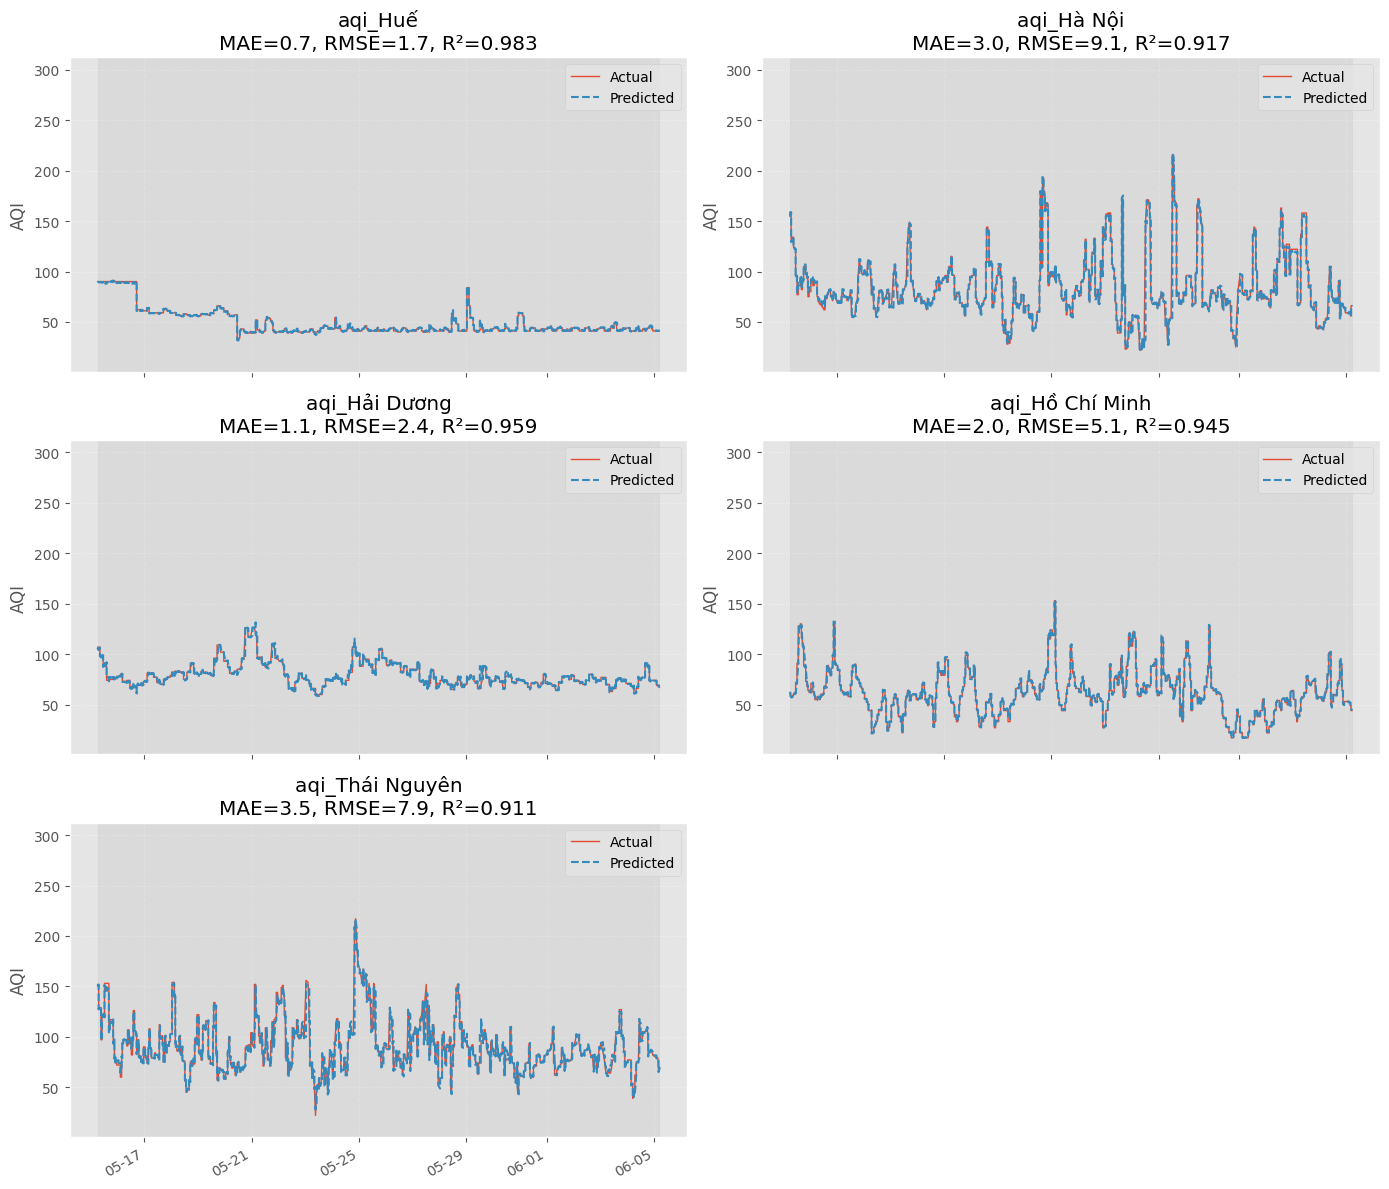

In [ ]:
# --- Chọn style ---
preferred = 'seaborn-darkgrid'
if preferred in plt.style.available:
    plt.style.use(preferred)
else:
    plt.style.use('ggplot')

# 1) Predict & inverse-transform
y_pred_scaled = model.predict(X_test)
y_pred = scaler.inverse_transform(y_pred_scaled)
y_true = scaler.inverse_transform(y_test)

# 2) Chuẩn bị timestamps cho test set
train_end = int(len(X_all) * 0.70)
test_start = df_wide.index[WINDOW + train_end]
test_end   = df_wide.index[WINDOW + train_end + len(y_test) - 1]
timestamps = df_wide.index[WINDOW + train_end : WINDOW + train_end + len(y_test)]

# 3) Layout
cities = [col for col in df_wide.columns if col.startswith("aqi_")]  # chỉ lấy AQI
n = len(cities)
cols = 2
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 4*rows), sharex=True)
axes = axes.flatten()

# 4) Xác định chung y-limits
y_min = df_wide.min().min() * 0.9
y_max = df_wide.max().max() * 1.1

for i, city in enumerate(cities):
    ax = axes[i]
    actual = y_true[:, i]
    pred   = y_pred[:, i]

    # Tính MAE, RMSE, R²
    mae_city  = mean_absolute_error(actual, pred)
    mse_city  = mean_squared_error(actual, pred)
    rmse_city = sqrt(mse_city)
    from sklearn.metrics import r2_score
    r2_city   = r2_score(actual, pred)

    # Vẽ
    ax.plot(timestamps, actual, label="Actual", linewidth=1)
    ax.plot(timestamps, pred,   label="Predicted", linestyle="--")
    ax.axvspan(test_start, test_end, color='gray', alpha=0.1)

    # Format
    ax.set_title(f"{city}\nMAE={mae_city:.1f}, RMSE={rmse_city:.1f}, R²={r2_city:.3f}")
    ax.set_ylabel("AQI")
    ax.set_ylim(y_min, y_max)
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.xaxis.set_major_locator(AutoDateLocator())
    ax.xaxis.set_major_formatter(DateFormatter("%m-%d"))

# Ẩn subplot thừa
for j in range(n, len(axes)):
    axes[j].axis("off")

plt.xlabel("Date")
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.show()

WINDOW = 14 LTSM

In [ ]:
# Đọc file CSV và chuyển timestamp về datetime
# --- Đọc & chuẩn bị dữ liệu chung ---
df2 = pd.read_csv(
    "/content/drive/MyDrive/Dataset/aqi_selected_cities_cleaned.csv",
    parse_dates=["timestamp"]
).query("city != 'Trà Vinh'")
df_aqi = df2.pivot(index="timestamp", columns="city", values="aqi")
df_pm25 = df2.pivot(index="timestamp", columns="city", values="pm25")

# Đặt lại tên cột để phân biệt
df_aqi.columns = [f"aqi_{col}" for col in df_aqi.columns]
df_pm25.columns = [f"pm25_{col}" for col in df_pm25.columns]

# Gộp 2 bảng lại
df_wide = pd.concat([df_aqi, df_pm25], axis=1).sort_index()
df_wide.fillna(method="ffill", inplace=True)
df_wide.dropna(how="any", inplace=True)
# 2) Scale toàn bộ dữ liệu (n_samples × 8)
scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(df_wide)

# 3) Tạo sequences multivariate
def create_multi_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i : i + window_size])
        y.append(data[i + window_size])       # y là vector 8 giá trị AQI của x city
    return np.array(X), np.array(y)

WINDOW = 14 # Bước 7 hoặc 14
X_all, y_all = create_multi_sequences(data_scaled, WINDOW)
# --- 4) Chia train / val / test ---
n = len(X_all)
train_end = int(n * 0.70)                # 70% cho train
val_end   = int(n * 0.85)                # thêm 15% cho val → tới 85%

X_train = X_all[:train_end]
y_train = y_all[:train_end]

X_val   = X_all[train_end:val_end]
y_val   = y_all[train_end:val_end]

X_test  = X_all[val_end:]
y_test  = y_all[val_end:]

print("Shapes:",
      "X_train", X_train.shape,
      "X_val",   X_val.shape,
      "X_test",  X_test.shape)
	  # --- 5) Xây dựng model---
model = Sequential([
    InputLayer((WINDOW, df_wide.shape[1])),
    LSTM(64),
    Dense(24, activation="relu"),
    Dense(df_wide.shape[1], activation="linear")
])
model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()
# --- 6) Huấn luyện với validation_data ---
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=16,
    callbacks=[ModelCheckpoint("best_multi.keras", save_best_only=True)]
)

# Sau training, bạn có thể đánh giá test:
model.load_weights("best_multi.keras")
mse_test, mae_test = model.evaluate(X_test, y_test, verbose=0)
print(f"Test MSE: {mse_test:.4f}, Test MAE: {mae_test:.4f}")
# --- 7) Đánh giá kết quả ---
model.load_weights("best_multi.keras")
y_pred_scaled = model.predict(X_test)

# Chuyển giá trị về thang gốc
y_pred = scaler.inverse_transform(y_pred_scaled)
y_true = scaler.inverse_transform(y_test)

# Tính MSE, MAE và R² trên thang gốc
mse = mean_squared_error(y_true, y_pred)
mae = mean_absolute_error(y_true, y_pred)
r2_true = r2_score(y_true, y_pred)
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R² (original scale): {r2_true:.2f}")


Shapes: X_train (11143, 14, 10) X_val (2388, 14, 10) X_test (2388, 14, 10)


/tmp/ipython-input-1270946015.py:16: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_wide.fillna(method="ffill", inplace=True)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        19,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24)             │         1,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,010 (82.07 KB)

 Trainable params: 21,010 (82.07 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 0.0179 - mae: 0.0789 - val_loss: 0.0012 - val_mae: 0.0219
Epoch 2/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 0.0012 - mae: 0.0229 - val_loss: 8.4912e-04 - val_mae: 0.0174
Epoch 3/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 9.1052e-04 - mae: 0.0187 - val_loss: 7.1759e-04 - val_mae: 0.0148
Epoch 4/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 7.5967e-04 - mae: 0.0164 - val_loss: 6.5077e-04 - val_mae: 0.0140
Epoch 5/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 7.2298e-04 - mae: 0.0154 - val_loss: 6.7206e-04 - val_mae: 0.0151
Epoch 6/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 6.8425e-04 - mae: 0.0146 - val_loss: 6.0543e-04 - val_mae: 0.0135
Epoch 7/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 6.6432e-04 - mae: 0.0139 - val_loss: 5.5196e-04 - val_mae: 0.0113
Epoch 8/50
697/697 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 6.1312e-04 - mae: 0.0128 - val_loss: 5.4002e-04 - val_mae: 0.0111
Epo

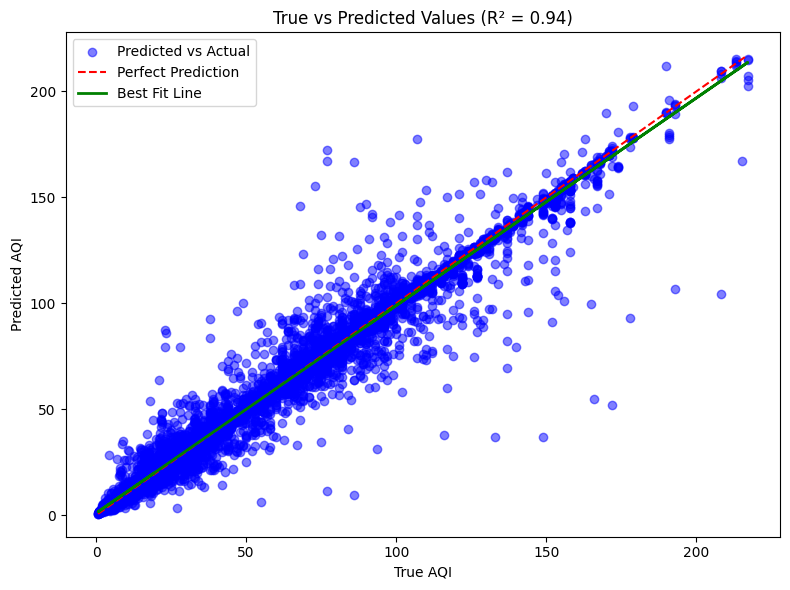

In [ ]:
# --- 9) Scatter True vs Predicted & Perfect Prediction ---
# Fit đường best-fit
lr = LinearRegression()
y_true_flat = y_true.flatten().reshape(-1, 1) # Flatten y_true and reshape for fitting
y_pred_flat = y_pred.flatten()               # Flatten y_pred
lr.fit(y_true_flat, y_pred_flat)
y_best_fit = lr.predict(y_true_flat)

# Vẽ scatter và hai đường
plt.figure(figsize=(8, 6))
plt.scatter(y_true_flat, y_pred_flat, color='blue', alpha=0.5, label="Predicted vs Actual") # Use flattened arrays for scatter plot

# Perfect Prediction line y = x (cùng thang gốc)
min_val = min(y_true_flat.min(), y_pred_flat.min())
max_val = max(y_true_flat.max(), y_pred_flat.max())
plt.plot([min_val, max_val], [min_val, max_val],
         color='red', linestyle='--', label="Perfect Prediction")

# Best-fit line
plt.plot(y_true_flat, y_best_fit,
         color='green', linestyle='-', linewidth=2, label="Best Fit Line")

plt.xlabel("True AQI")
plt.ylabel("Predicted AQI")
plt.title(f"True vs Predicted Values (R² = {r2_true:.2f})")
plt.legend()
plt.tight_layout()
plt.show()

**RANDOM FOREST**

In [ ]:
import pandas as pd
import numpy as np
from math import sqrt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- Cấu hình ---
WINDOW         = 7
exog_vars      = ["pm25"]
LAG_EXOG       = [1, 3, 6, 12]
LAG_AQI        = list(range(1, WINDOW+1))
n_splits       = 5
n_splits_search = 2
n_iter_search  = 10

param_dist = {
    "n_estimators":      [200, 375, 500],
    "max_depth":         [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "max_features":      ["sqrt", "log2", 0.3],
}

# --- Đọc & chuẩn bị dữ liệu ---
df = pd.read_csv(
    "/content/drive/MyDrive/Dataset/aqi_selected_cities_cleaned.csv",
    parse_dates=["timestamp"]
).query("city != 'Trà Vinh'")

# Bổ sung thông tin thời gian
df["hour"]      = df.timestamp.dt.hour
df["hour_sin"]  = np.sin(2*np.pi*df.hour/24)
df["hour_cos"]  = np.cos(2*np.pi*df.hour/24)
df["weekday"]   = df.timestamp.dt.weekday
df["month"]     = df.timestamp.dt.month
df["month_sin"] = np.sin(2*np.pi*df.month/12)
df["month_cos"] = np.cos(2*np.pi*df.month/12)

# --- Gộp dữ liệu toàn bộ thành phố ---
dfs = []
for city in df.city.unique():
    df_c = df[df.city == city].copy().sort_values("timestamp")

    # Feature engineering
    for v in exog_vars:
        for lag in LAG_EXOG:
            df_c[f"{v}_lag{lag}"] = df_c[v].shift(lag)
        df_c[f"{v}_roll3_mean"] = df_c[v].rolling(3).mean()
        df_c[f"{v}_roll3_std"]  = df_c[v].rolling(3).std()
    for lag in LAG_AQI:
        df_c[f"aqi_lag{lag}"] = df_c.aqi.shift(lag)

    df_c["target_aqi"] = df_c.aqi.shift(-1)
    dfs.append(df_c)

# Gộp tất cả
df_all = pd.concat(dfs).dropna().sort_values("timestamp").reset_index(drop=True)

# Danh sách feature
feature_cols = (
      exog_vars
    + [f"{v}_lag{lag}"     for v in exog_vars for lag in LAG_EXOG]
    + [f"{v}_roll3_mean"   for v in exog_vars]
    + [f"{v}_roll3_std"    for v in exog_vars]
    + [f"aqi_lag{lag}"     for lag in LAG_AQI]
    + ["hour_sin", "hour_cos", "weekday", "month_sin", "month_cos"]
)

X = df_all[feature_cols]
y = df_all["target_aqi"]

# --- Subsample cho tuning (25%) ---
subsample_size = int(len(X)*0.25)
idx = np.random.RandomState(42).choice(len(X), size=subsample_size, replace=False)
X_tune, y_tune = X.iloc[idx], y.iloc[idx]

# --- Tuning hyperparameters ---
#print("🔧 Tuning hyperparams trên 25% data (toàn bộ city)…")
tscv_search = TimeSeriesSplit(n_splits=n_splits_search)
base_rf = RandomForestRegressor(random_state=42, n_jobs=-1)
search = RandomizedSearchCV(
    estimator=base_rf,
    param_distributions=param_dist,
    n_iter=n_iter_search,
    cv=tscv_search,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    random_state=42
)
search.fit(X_tune, y_tune)
best_params = search.best_params_
#print("✅ Best params:", best_params)

# --- Chia dữ liệu ---
n = len(X)
train_end = int(n * 0.7)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

# Gộp train + val (giống cách huấn luyện LSTM rồi đánh giá test riêng)
X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

# --- Huấn luyện với best_params từ RandomizedSearchCV ---
model = RandomForestRegressor(**best_params, random_state=42, n_jobs=-1)
model.fit(X_trainval, y_trainval)

# --- Dự đoán trên tập test ---
y_pred = model.predict(X_test)

# --- Đánh giá ---
mse = mean_squared_error(y_test, y_pred)
rmse = sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n===== Kết quả RF Test =====")
print(f"R²   : {r2:.3f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")


===== Kết quả RF Test =====
R²   : 0.751
RMSE : 13.58
MAE  : 7.59
MSE  : 184.35


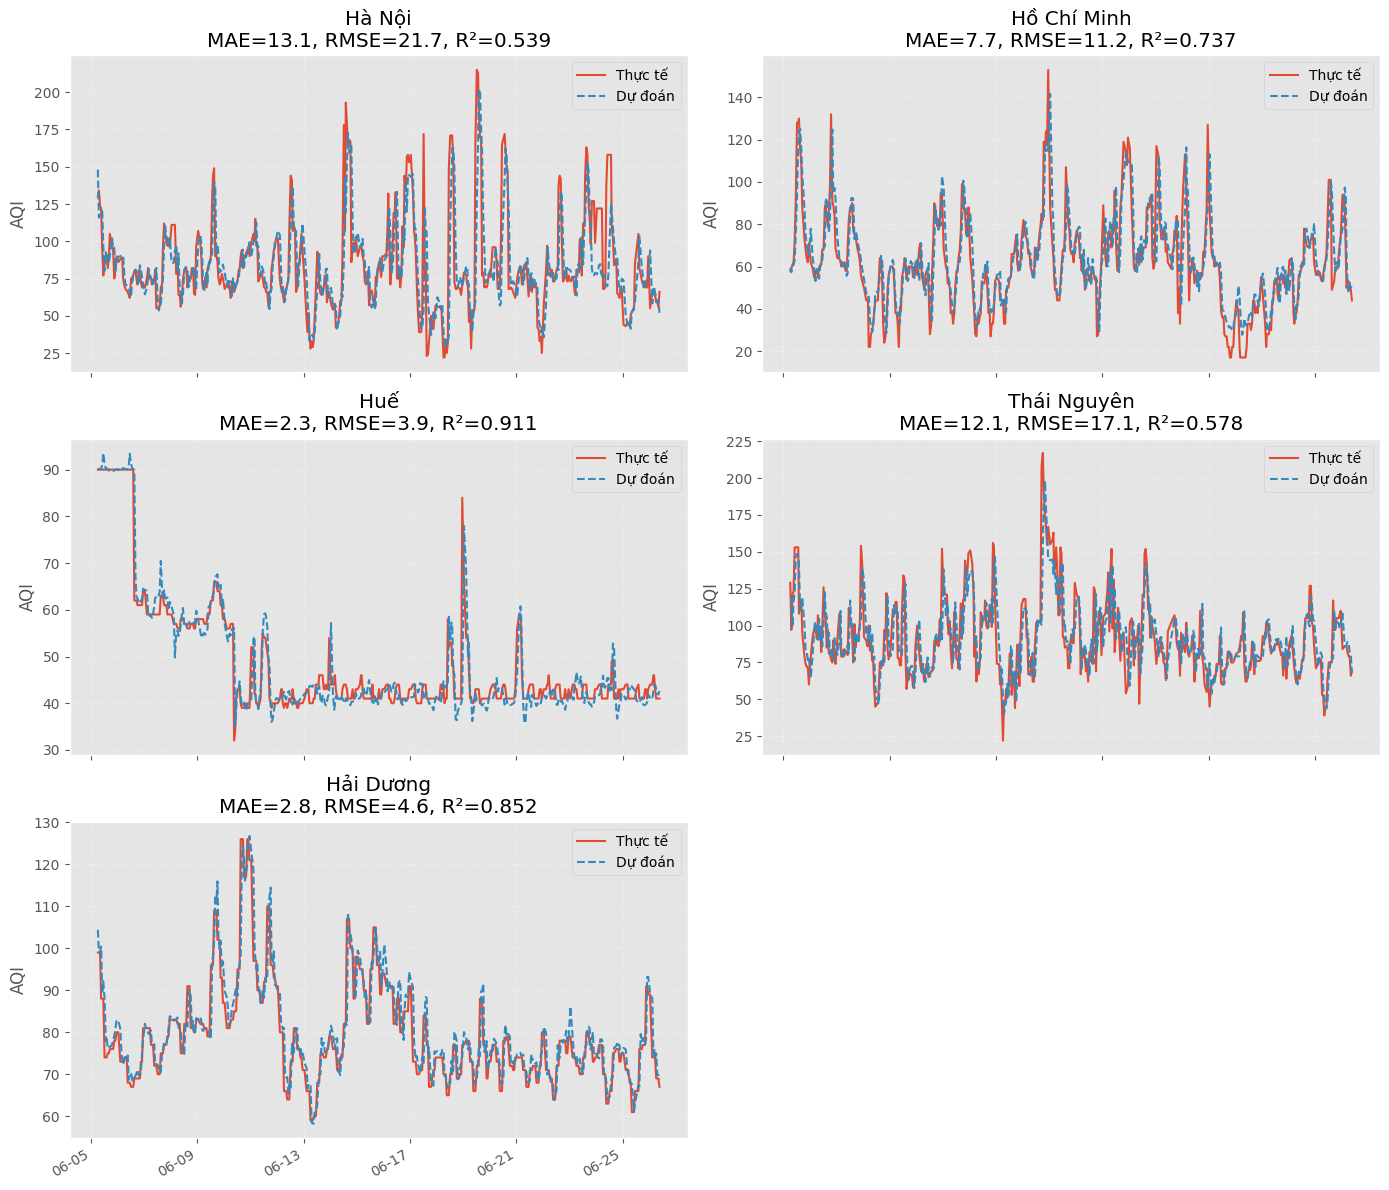

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from math import sqrt
from matplotlib.dates import DateFormatter, AutoDateLocator

# Giữ lại dữ liệu test và city tương ứng
df_test = df_all.iloc[val_end:].copy()
df_test["y_true"] = y_test.values
df_test["y_pred"] = y_pred

# Danh sách thành phố
cities = df_test["city"].unique()
n = len(cities)
cols = 2
rows = int(np.ceil(n / cols))

# Cấu hình plot
plt.style.use("ggplot")
fig, axes = plt.subplots(rows, cols, figsize=(14, 4*rows), sharex=False)
axes = axes.flatten()

for i, city in enumerate(cities):
    ax = axes[i]
    df_city = df_test[df_test["city"] == city]

    ts = df_city["timestamp"]
    actual = df_city["y_true"]
    pred   = df_city["y_pred"]

    mae_city  = mean_absolute_error(actual, pred)
    rmse_city = sqrt(mean_squared_error(actual, pred))
    r2_city   = r2_score(actual, pred)

    ax.plot(ts, actual, label="Thực tế", linewidth=1.5)
    ax.plot(ts, pred, linestyle="--", label="Dự đoán")

    ax.set_title(f"{city}\nMAE={mae_city:.1f}, RMSE={rmse_city:.1f}, R²={r2_city:.3f}")
    ax.set_ylabel("AQI")
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.xaxis.set_major_locator(AutoDateLocator())
    ax.xaxis.set_major_formatter(DateFormatter("%m-%d"))

# Ẩn subplot thừa
for j in range(n, len(axes)):
    axes[j].axis("off")

plt.xlabel("Ngày")
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.show()

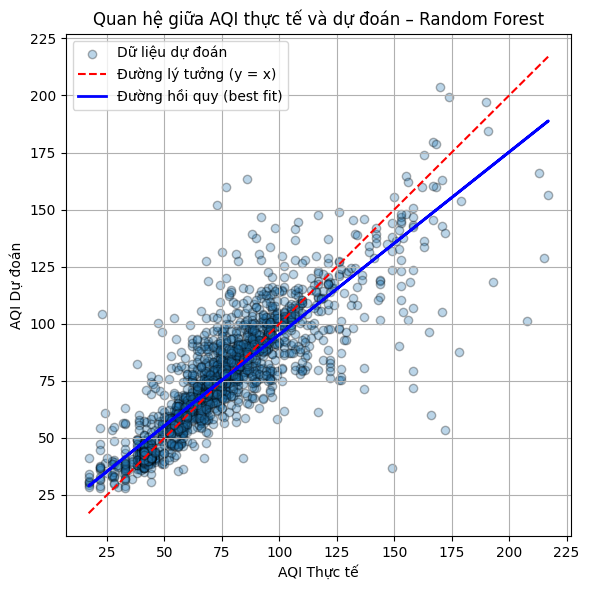

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression

# Reshape lại để fit model
y_test_reshape = np.array(y_test).reshape(-1, 1)
y_pred_reshape = np.array(y_pred).reshape(-1, 1)

# Fit đường hồi quy
reg = LinearRegression().fit(y_test_reshape, y_pred_reshape)
y_fit = reg.predict(y_test_reshape)

# Vẽ biểu đồ
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.3, edgecolor='k', label="Dữ liệu dự đoán")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label="Đường lý tưởng (y = x)")
plt.plot(y_test, y_fit, color='blue', linewidth=2, label="Đường hồi quy (best fit)")
plt.xlabel("AQI Thực tế")
plt.ylabel("AQI Dự đoán")
plt.title("Quan hệ giữa AQI thực tế và dự đoán – Random Forest")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


RF = 14

In [ ]:
import pandas as pd
import numpy as np
from math import sqrt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- Cấu hình ---
WINDOW         = 14
exog_vars      = ["pm25"]
LAG_EXOG       = [1, 3, 6, 12]
LAG_AQI        = list(range(1, WINDOW+1))
n_splits       = 5
n_splits_search = 2
n_iter_search  = 10

param_dist = {
    "n_estimators":      [200, 375, 500],
    "max_depth":         [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "max_features":      ["sqrt", "log2", 0.3],
}

# --- Đọc & chuẩn bị dữ liệu ---
df = pd.read_csv(
    "/content/drive/MyDrive/Dataset/aqi_selected_cities_cleaned.csv",
    parse_dates=["timestamp"]
).query("city != 'Trà Vinh'")

# Bổ sung thông tin thời gian
df["hour"]      = df.timestamp.dt.hour
df["hour_sin"]  = np.sin(2*np.pi*df.hour/24)
df["hour_cos"]  = np.cos(2*np.pi*df.hour/24)
df["weekday"]   = df.timestamp.dt.weekday
df["month"]     = df.timestamp.dt.month
df["month_sin"] = np.sin(2*np.pi*df.month/12)
df["month_cos"] = np.cos(2*np.pi*df.month/12)

# --- Gộp dữ liệu toàn bộ thành phố ---
dfs = []
for city in df.city.unique():
    df_c = df[df.city == city].copy().sort_values("timestamp")

    # Feature engineering
    for v in exog_vars:
        for lag in LAG_EXOG:
            df_c[f"{v}_lag{lag}"] = df_c[v].shift(lag)
        df_c[f"{v}_roll3_mean"] = df_c[v].rolling(3).mean()
        df_c[f"{v}_roll3_std"]  = df_c[v].rolling(3).std()
    for lag in LAG_AQI:
        df_c[f"aqi_lag{lag}"] = df_c.aqi.shift(lag)

    df_c["target_aqi"] = df_c.aqi.shift(-1)
    dfs.append(df_c)

# Gộp tất cả
df_all = pd.concat(dfs).dropna().sort_values("timestamp").reset_index(drop=True)

# Danh sách feature
feature_cols = (
      exog_vars
    + [f"{v}_lag{lag}"     for v in exog_vars for lag in LAG_EXOG]
    + [f"{v}_roll3_mean"   for v in exog_vars]
    + [f"{v}_roll3_std"    for v in exog_vars]
    + [f"aqi_lag{lag}"     for lag in LAG_AQI]
    + ["hour_sin", "hour_cos", "weekday", "month_sin", "month_cos"]
)

X = df_all[feature_cols]
y = df_all["target_aqi"]

# --- Subsample cho tuning (25%) ---
subsample_size = int(len(X)*0.25)
idx = np.random.RandomState(42).choice(len(X), size=subsample_size, replace=False)
X_tune, y_tune = X.iloc[idx], y.iloc[idx]

# --- Tuning hyperparameters ---
#print("🔧 Tuning hyperparams trên 25% data (toàn bộ city)…")
tscv_search = TimeSeriesSplit(n_splits=n_splits_search)
base_rf = RandomForestRegressor(random_state=42, n_jobs=-1)
search = RandomizedSearchCV(
    estimator=base_rf,
    param_distributions=param_dist,
    n_iter=n_iter_search,
    cv=tscv_search,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    random_state=42
)
search.fit(X_tune, y_tune)
best_params = search.best_params_
#print("✅ Best params:", best_params)

# --- Chia dữ liệu ---
n = len(X)
train_end = int(n * 0.7)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

# Gộp train + val (giống cách huấn luyện LSTM rồi đánh giá test riêng)
X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

# --- Huấn luyện với best_params từ RandomizedSearchCV ---
model = RandomForestRegressor(**best_params, random_state=42, n_jobs=-1)
model.fit(X_trainval, y_trainval)

# --- Dự đoán trên tập test ---
y_pred = model.predict(X_test)

# --- Đánh giá ---
mse = mean_squared_error(y_test, y_pred)
rmse = sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n===== Kết quả RF Test =====")
print(f"R²   : {r2:.3f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")


===== Kết quả RF Test =====
R²   : 0.750
RMSE : 13.60
MAE  : 7.64
MSE  : 184.95
